## VLM vqa 2 views recsession 5

- VLM is glm-5.3-flash
- evaluated on videos for which in theory 2 views are absolutely necessary for correct classification
- videos form recording session 5 (total 27 videos)
- Each video is given a custom label space of 7-10 classes closely related to actual class


In [3]:
## conda env vgd has openai
import base64
import os
import json
import time
from dotenv import load_dotenv
from openai import OpenAI
import pandas as pd
import numpy as np
from tqdm import tqdm

import cv2

In [4]:
# Setting the max characters to be displayed
pd.set_option('display.max_colwidth', None)

# display full dataframe pandas / output window widened
pd.set_option('display.width', 10000) # None

# Setting the precision for float columns
pd.set_option('display.precision', 2)

# Preparing main index_df with vqa videos

In [5]:
## index_df
index_df = pd.read_csv('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/hamza_vgd_data/capture/index.csv')
print(index_df.shape)

index_df = index_df[index_df['session'].str.startswith('vqa')].reset_index(drop=True)
print(index_df.shape)

index_df['cam'] = 'cam1'
index_df = index_df.rename(columns={'id':'video_id'})

print(index_df.shape)
index_df.head(2)

(196, 4)
(29, 4)
(29, 5)


,video_id,template,placeholders,session,cam
0,261027-131511,Moving [something] across a surface,wallet,vqa_wallet_clean,cam1
1,261027-131534,Moving [something] across a surface until it falls down,wallet,vqa_wallet_clean,cam1


In [6]:
labels_list = index_df.template.unique().tolist()
labels_list.sort()

index_df.template.value_counts()

template
Tearing [something] and throwing it in the bin                       3
Moving [something] across a surface                                  2
Moving [something] across a surface until it falls down              2
Moving [something] across a surface until it hits [something]        2
Rolling [something] on a surface and stop it with hand               2
Picking [something] up then putting it down upright                  2
Picking [something] up and deforming it                              2
Picking [something] up while putting [something] down                2
Rolling [something] across a surface until it hits [something]       2
Throwing [something] in the [something]                              2
Throwing [something] on the ground                                   2
Picking [something] up then laying it down on its side               1
Rolling [something] across a surface until it falls down             1
Tearing [something] and then kicking the bin                        

### select videos

In [7]:
## special session
index_df['session_special'] = np.where(index_df.session.isin(['plug_2','magnet_2','lady_2','books_2']), 'distractors_in_video',
                               np.where(index_df.session.isin(['plug_1','magnet_1','lady_1','books_1','paper_1']), 'session_1_control', 
                                        np.where(index_df.session.isin(['plugging_1','showing_photo_of_1','attaching_1','piling_1']), 'session2_specialActions_commonobjects',
                                                 np.where(index_df['session'].str.startswith('endProduct'), 'distractors_are_endproducts',
                                                    np.where(index_df['session'].str.startswith('vqa'), 'vqa',
                                                        np.where(index_df['session'].str.startswith('mime'), 'miming_videos', 
                                                              'mime_actions_control_videos'))))))

index_df.tail(2)

,video_id,template,placeholders,session,cam,session_special
27,261103-104714,Throwing [something] on the ground,board marker,vqa2_recsession5,cam1,vqa
28,261103-104955,Throwing [something] on the ground,wallet,vqa2_recsession5,cam1,vqa


In [8]:
for i, row in index_df[index_df.session_special.isin(['vqa'])].iterrows():
    print(f"'{row['video_id']}', # {row['session_special']} | {row['placeholders']} --> {row['template']:15} ")


'261027-131511', # vqa | wallet --> Moving [something] across a surface 
'261027-131534', # vqa | wallet --> Moving [something] across a surface until it falls down 
'261027-132224', # vqa | wallet, books --> Moving [something] across a surface until it hits [something] 
'261027-132321', # vqa | wallet --> Moving [something] across a surface 
'261027-132344', # vqa | wallet --> Moving [something] across a surface until it falls down 
'261027-132411', # vqa | wallet, books --> Moving [something] across a surface until it hits [something] 
'261027-132808', # vqa | ball --> Rolling [something] on a surface and stop it with hand 
'261027-133237', # vqa | paper --> Tearing [something] and throwing it in the bin 
'261027-134525', # vqa | board marker --> Rolling [something] on a surface and stop it with hand 
'261027-134559', # vqa | ball --> Tearing [something] and throwing it in the bin 
'261103-100414', # vqa | water bottle --> Picking [something] up then putting it down upright 
'261103-

In [9]:
vids_list = [
    '261027-131534', # vqa | wallet --> Moving [something] across a surface until it falls down 
    '261027-132224', # vqa | wallet, books --> Moving [something] across a surface until it hits [something] 
    '261027-132344', # vqa | wallet --> Moving [something] across a surface until it falls down 
    '261027-132411', # vqa | wallet, books --> Moving [something] across a surface until it hits [something] 
    '261027-132808', # vqa | ball --> Roll [something] on table and stop it with hand 
    '261027-134525', # vqa | board marker --> Roll [something] on table and stop it with hand 
    '261027-133237', # vqa | paper --> Tearing [something] and throwing it in the bin 
    '261027-134559', # vqa | ball --> Tearing [something] and throwing it in the bin

    '261103-100414', # vqa | water bottle --> Picking [something] up then putting it down upright 
    '261103-100546', # vqa | cup --> Picking [something] up then putting it down upright 
    '261103-100645', # vqa | tissue paper --> Picking [something] up and deforming it 
    '261103-100711', # vqa | paper --> Picking [something] up and deforming it 
    '261103-100744', # vqa | cup --> Picking [something] up then laying it down on its side 
    '261103-101050', # vqa | pen, board marker --> Picking [something] up while putting [something] down 
    '261103-101141', # vqa | magnet, phone --> Picking [something] up while putting [something] down 
    '261103-101219', # vqa | ball, books --> Rolling [something] across a surface until it hits [something] 
    '261103-101252', # vqa | water bottle, electrical extension --> Rolling [something] across a surface until it hits [something] 
    '261103-101318', # vqa | ball --> Rolling [something] across a surface until it falls down 
    '261103-101415', # vqa | tissue paper --> Tearing [something] and throw it in the bin 
    '261103-101508', # vqa | paper --> Tearing [something] and then kicking the bin 
    '261103-102619', # vqa | ball, bin --> Throwing [something] in the [something] 
    '261103-104129', # vqa | wallet --> Throwing [something] on a surface so it rests 
    '261103-104146', # vqa | ball --> Throwing [something] on a surface so it bounces off  and falls 
    '261103-104517', # vqa | ball --> Throwing [something] on a surface and catching it with other hand 
    '261103-104630', # vqa | pen, cardboard box --> Throwing [something] in the [something] 
    '261103-104714', # vqa | board marker --> Throwing [something] on the ground 
    '261103-104955', # vqa | wallet --> Throwing [something] on the ground 
]

In [9]:
import shutil
# ------------- chunk to copy videos ------------- #
source_dir = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/hamza_vgd_data/capture/"
dest_dir = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/zz_temp_dump/"

# 2. Clear destination directory if it exists, then recreate it
if os.path.exists(dest_dir):
    shutil.rmtree(dest_dir)
os.makedirs(dest_dir, exist_ok=True)

# 3. Get unique video IDs and copy matching files
unique_video_ids = vids_list

for filename in os.listdir(source_dir):
    if any(video_id in filename for video_id in unique_video_ids):
        shutil.copy(os.path.join(source_dir, filename), os.path.join(dest_dir, filename))
# ------------------------------------------------ #

# Create Special Label Space per video

In [10]:
TemplateStart2LabelSpace = {

    'Moving [something]': [
        "Moving [something] across a surface until it falls down", 
        "Moving [something] across a surface until it hits [something]",
        "Moving [something] across a surface and then stop moving it",
        "Moving [something] across a surface with both hands",
        "Moving [something] in the air and dropping it",
        "Moving [something] in the air and placing it down",
        "Moving [something] across a surface with [something]",
        "Throwing [something] on a surface",
        "Pretending to move [something] across a surface",

    ],
    'Rolling [something]': [
        "Rolling [something] across a surface until it hits [something]",
        "Rolling [something] on a surface and stop it with hand",
        "Rolling [something] across a surface until it falls down",
        "Rolling [something] back and forth across a surface",
        "Throwing [something] on a surface",
        "Pretending to roll [something] across a surface",
        "Rolling [something] across a surface till it breaks",
        "Unfolding [something] across a surface",
        
    ],
    'Picking [something] up': [
        "Picking [something] up then putting it down upright",
        "Picking [something] up and deforming it",
        "Picking [something] up while putting [something] down",
        "Picking [something] up then laying it down on its side",
        "Pretending to pick [something] up",
        "Picking [something] up and taking it out of the view completely",
        "Picking [something] up and throwing it in the bin",
        "Picking [something] up and tearing it into two pieces",
    ],
    'Tearing [something]': [
        "Tearing [something] and throwing it in the bin",
        "Tearing [something] and then kicking the bin",
        "Tearing [something] and throwing it in the carboard box",
        "Tearing [something] and putting pieces on the table",
        "Tearing [something] and putting it back together",
        "Tearing [something] and throwing it out of the window",
        "Pretending to tear [something]",
        "Shredding [something] into many pieces and throwing in the bin",

    ],
    'Throwing [something]': [
        "Throwing [something] in the [something]",
        "Throwing [something] on the ground",
        "Throwing [something] on a surface so it rests",
        "Throwing [something] on a surface so it bounces off  and falls",
        "Throwing [something] on a surface and catching it with other hand",
        "Throwing [something] at the wall so it bounces back",
        "Throwing [something] up in air and wait for it to fall down",
        "Throwing [something] up in the air and catching it",
        "Moving [something] across a surface with [something]",
        "Tearing [something] into two pieces",

    ],

}

In [11]:
index_df['LabelSpace'] = ''

for key in TemplateStart2LabelSpace:
    labspace = TemplateStart2LabelSpace[key]
    index_df['LabelSpace'] = np.where(index_df['template'].str.startswith(key), str(labspace), index_df['LabelSpace'])

index_df.sample(2)

,video_id,template,placeholders,session,cam,session_special,LabelSpace
28,261103-104955,Throwing [something] on the ground,wallet,vqa2_recsession5,cam1,vqa,"['Throwing [something] in the [something]', 'Throwing [something] on the ground', 'Throwing [something] on a surface so it rests', 'Throwing [something] on a surface so it bounces off and falls', 'Throwing [something] on a surface and catching it with other hand', 'Throwing [something] at the wall so it bounces back', 'Throwing [something] up in air and wait for it to fall down', 'Throwing [something] up in the air and catching it', 'Moving [something] across a surface with [something]', 'Tearing [something] into two pieces']"
26,261103-104630,Throwing [something] in the [something],"pen, cardboard box",vqa2_recsession5,cam1,vqa,"['Throwing [something] in the [something]', 'Throwing [something] on the ground', 'Throwing [something] on a surface so it rests', 'Throwing [something] on a surface so it bounces off and falls', 'Throwing [something] on a surface and catching it with other hand', 'Throwing [something] at the wall so it bounces back', 'Throwing [something] up in air and wait for it to fall down', 'Throwing [something] up in the air and catching it', 'Moving [something] across a surface with [something]', 'Tearing [something] into two pieces']"


In [12]:
index_df['LabelSpace'][9]

"['Tearing [something] and throwing it in the bin', 'Tearing [something] and then kicking the bin', 'Tearing [something] and throwing it in the carboard box', 'Tearing [something] and putting pieces on the table', 'Tearing [something] and putting it back together', 'Tearing [something] and throwing it out of the window', 'Pretending to tear [something]', 'Shredding [something] into many pieces and throwing in the bin']"

In [13]:
index_df['LabelSpace'].value_counts()

LabelSpace
['Picking [something] up then putting it down upright', 'Picking [something] up and deforming it', 'Picking [something] up while putting [something] down', 'Picking [something] up then laying it down on its side', 'Pretending to pick [something] up', 'Picking [something] up and taking it out of the view completely', 'Picking [something] up and throwing it in the bin', 'Picking [something] up and tearing it into two pieces']                                                                                                             7
['Throwing [something] in the [something]', 'Throwing [something] on the ground', 'Throwing [something] on a surface so it rests', 'Throwing [something] on a surface so it bounces off  and falls', 'Throwing [something] on a surface and catching it with other hand', 'Throwing [something] at the wall so it bounces back', 'Throwing [something] up in air and wait for it to fall down', 'Throwing [something] up in the air and catching it', 'Moving [some

# VLM Evaluation for VQA dataset

- 2 cam views important to classify action. cam0 and cam1.

#### Concatenate the 2 views per video carefully

- Because glm-5.3-Flash cannot ingest 2 separate videos at the same time

In [14]:
def concatenate_videos_side_by_side(video_path_0, video_path_1, output_path):
    """Stitches two synchronized videos horizontally into a single video file."""
    if os.path.exists(output_path):
        print(f"[-] Skipping concatenation: '{output_path}' already exists.")
        return
    
    cap0 = cv2.VideoCapture(video_path_0)
    cap1 = cv2.VideoCapture(video_path_1)

    fps = cap0.get(cv2.CAP_PROP_FPS) or 30.0
    width0 = int(cap0.get(cv2.CAP_PROP_FRAME_WIDTH))
    height0 = int(cap0.get(cv2.CAP_PROP_FRAME_HEIGHT))
    height1 = int(cap1.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Match height of video 1 to video 0 if they differ
    target_height = height0

    fourcc = cv2.VideoWriter_fourcc(*'XVID')
    # Combined width = width of cam0 + width of cam1
    out_width = width0 + int(cap1.get(cv2.CAP_PROP_FRAME_WIDTH) * (target_height / height1))
    out = cv2.VideoWriter(output_path, fourcc, fps, (out_width, target_height))

    while cap0.isOpened() and cap1.isOpened():
        ret0, frame0 = cap0.read()
        ret1, frame1 = cap1.read()

        if not ret0 or not ret1:
            break

        # Resize frame1 if heights don't match exactly
        if frame1.shape[0] != target_height:
            new_w = int(frame1.shape[1] * (target_height / frame1.shape[0]))
            frame1 = cv2.resize(frame1, (new_w, target_height))

        # Concatenate horizontally (Left: View 0 | Right: View 1)
        combined_frame = cv2.hconcat([frame0, frame1])
        out.write(combined_frame)

    cap0.release()
    cap1.release()
    out.release()

    print(f"[*] New file created: {output_path}")

In [51]:
# File paths
videos_file_path = '/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/hamza_vgd_data/capture/raw/'
combined_videos_file_path = 'data/combined_videos/'

for video_name in vids_list:
    path_cam0 = f"{videos_file_path}{video_name}_cam0.avi"
    path_cam1 = f"{videos_file_path}{video_name}_cam1.avi"
    combined_path = f"{combined_videos_file_path}{video_name}_combined.avi"

    # Stitch the videos horizontally
    concatenate_videos_side_by_side(path_cam0, path_cam1, combined_path)

[-] Skipping concatenation: 'data/combined_videos/261027-131534_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-132224_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-132344_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-132411_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-132808_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-134525_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-133237_combined.avi' already exists.
[-] Skipping concatenation: 'data/combined_videos/261027-134559_combined.avi' already exists.
[*] New file created: data/combined_videos/261103-100414_combined.avi
[*] New file created: data/combined_videos/261103-100546_combined.avi
[*] New file created: data/combined_videos/261103-100645_combined.avi
[*] New file created: data/combined_vi

### Run one video

In [79]:
# Load environment variables from .env
load_dotenv()

client = OpenAI(
    api_key=os.getenv("GWDG_OPENAI_API_KEY"), 
    base_url="https://chat-ai.academiccloud.de/v1"
    )
client

In [15]:
# Encode combined video to base64
video_name = vids_list[20]

combined_path = f'data/combined_videos/{video_name}_combined.avi'

with open(combined_path, "rb") as f:
    b64_combined_video = base64.b64encode(f.read()).decode("utf-8")

In [16]:
labels_list_for_video = eval(index_df[index_df.video_id==video_name]["LabelSpace"].item())

In [ ]:
def generate_custom_prompts(labels_list=labels_list_for_video):
    system_prompt = (
        "You are an expert multi-view video action classification model. "
        "You are provided with a single video frame containing two side-by-side synchronized camera views of the exact same temporal event: "
        "the LEFT half is 'View 0' and the RIGHT half is 'View 1'. "
        "You must synthesize spatial and temporal information across both views to classify the primary action."
    )

    user_prompt = f"""
    Analyze this synchronized multi-view video containing two camera angles (LEFT side: View 0, RIGHT side: View 1) of the exact same temporal event and classify the action performed.

    Candidate Action Classes:
    {json.dumps(labels_list, indent=2)}

    Instructions:
    1. Synthesize the sequence of events across BOTH camera halves (Left = View 0, Right = View 1). A single view cannot determine the true class.
    2. Assign an integer rank from 1 to {len(labels_list)} to EVERY candidate class (where 1 is the most likely action class and {len(labels_list)} is the least likely). Each rank from 1 to {len(labels_list)} must be used exactly once with no ties.
    3. Select the top predicted class name based on the combined multi-view evidence (the class assigned Rank 1).
    4. Provide a brief visual observation for View 0 (Left), View 1 (Right), and how they temporally connect.

    Output strictly in JSON matching this schema:
    {{
      "view_0_observation": "<1-sentence visual description of View 0 (Left side)>",
      "view_1_observation": "<1-sentence visual description of View 1 (Right side)>",
      "combined_reasoning": "<1-sentence explanation of how both views complement each other to reveal the true action>",
      "predicted_class": "<exact class name assigned Rank 1>",
      "ranks": {{
        "{labels_list[0]}": 1,
        "{labels_list[1]}": 2,
        "...": 3
      }}
    }}
    """

    return system_prompt, user_prompt


system_prompt, user_prompt = generate_custom_prompts(labels_list=labels_list_for_video)
print(user_prompt)


    Analyze this synchronized multi-view video containing two camera angles (LEFT side: View 0, RIGHT side: View 1) of the exact same temporal event and classify the action performed.

    Candidate Action Classes:
    [
  "Throwing [something] in the [something]",
  "Throwing [something] on the ground",
  "Throwing [something] on a surface so it rests",
  "Throwing [something] on a surface so it bounces off  and falls",
  "Throwing [something] on a surface and catching it with other hand",
  "Throwing [something] at the wall so it bounces back",
  "Throwing [something] up in air and wait for it to fall down",
  "Throwing [something] up in the air and catching it",
  "Moving [something] across a surface with [something]",
  "Tearing [something] into two pieces"
]

    Instructions:
    1. Synthesize the sequence of events across BOTH camera halves (Left = View 0, Right = View 1). A single view cannot determine the true class.
    2. Assign an integer rank from 1 to 10 to EVERY candida

In [82]:
start_time = time.time()

response = client.chat.completions.create(
    model="glm-5.3-flash",
    messages=[
        {"role": "system", "content": system_prompt},
        {
            "role": "user",
            "content": [
                {"type": "text", "text": user_prompt},
                {
                    "type": "video_url",
                    "video_url": {"url": f"data:video/avi;base64,{b64_combined_video}"},
                },
            ],
        },
    ],
    response_format={"type": "json_object"},
    temperature=0.1,
)

elapsed_time = round(time.time() - start_time, 2)

print(f"Elapsed time: {elapsed_time}s")

Elapsed time: 8.63s


In [83]:
prediction_json = json.loads(response.choices[0].message.content)
prediction_json.keys()

dict_keys(['view_0_observation', 'view_1_observation', 'combined_reasoning', 'predicted_class', 'ranks'])

In [84]:
# Extract JSON prediction content
prediction_json = json.loads(response.choices[0].message.content)

# Extract token & performance metadata
usage = response.usage

# 3. Update the dictionary to log both video file names
run_result = {
    "video_file": os.path.basename(combined_path),
    "model": response.model,
    "elapsed_seconds": elapsed_time,
    "prompt_tokens": usage.prompt_tokens if usage else None,
    "completion_tokens": usage.completion_tokens if usage else None,
    "total_tokens": usage.total_tokens if usage else None,
    "predicted_class": prediction_json.get("predicted_class"),
    "view_0_observation": prediction_json.get("view_0_observation"),
    "view_1_observation": prediction_json.get("view_1_observation"),
    "combined_reasoning": prediction_json.get("combined_reasoning"),
    "ranks": prediction_json.get("ranks", {}),
}

# Append result as a single JSON line
with open('data/vlm_eval_results/action_predictions_vqa_2views_recsession5.jsonl', "a", encoding="utf-8") as f:
    f.write(json.dumps(run_result) + "\n")

print(json.dumps(run_result, indent=2))

{
  "video_file": "261103-102619_combined.avi",
  "model": "glm-5.3-flash",
  "elapsed_seconds": 8.63,
  "prompt_tokens": 5363,
  "completion_tokens": 725,
  "total_tokens": 6088,
  "predicted_class": "Throwing [something] in the [something]",
  "view_0_observation": "A hand holds a yellow tennis ball and then releases/throws it forward over a wooden floor, with the hand dropping out of frame after the release.",
  "view_1_observation": "A black trash bin with a plastic liner sits next to an open cardboard box on blue carpet, and the yellow tennis ball is seen falling into the bin's opening.",
  "combined_reasoning": "View 0 shows the person throwing the tennis ball, while View 1 reveals the target and outcome \u2014 the ball lands inside the trash bin \u2014 confirming the action is throwing something into a container.",
  "ranks": {
    "Throwing [something] in the [something]": 1,
    "Throwing [something] on the ground": 2,
    "Throwing [something] on a surface so it rests": 3,
  

## Main Experiment: For loop over many videos

In [110]:
# Load environment variables from .env
load_dotenv()

client = OpenAI(
    api_key=os.getenv("GWDG_OPENAI_API_KEY"), 
    base_url="https://chat-ai.academiccloud.de/v1"
    )

In [111]:
from tqdm import tqdm

videos_dir = 'data/combined_videos/'

pbar = tqdm(vids_list, desc="Processing Videos")

for video_name in pbar:
    # Make file path and load video in base64 format
    combined_path = videos_dir + video_name + '_combined.avi'
    with open(combined_path, "rb") as f:
        b64_combined_video = base64.b64encode(f.read()).decode("utf-8")

    # generate prompts
    labels_list_for_video = eval(index_df[index_df.video_id==video_name]["LabelSpace"].item())
    system_prompt, user_prompt = generate_custom_prompts(labels_list=labels_list_for_video)
    
    # API call
    start_time = time.time()

    response = client.chat.completions.create(
        model="glm-5.3-flash",
        messages=[
            {"role": "system", "content": system_prompt},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": user_prompt},
                    {
                        "type": "video_url",
                        "video_url": {"url": f"data:video/avi;base64,{b64_combined_video}"},
                    },
                ],
            },
        ],
        response_format={"type": "json_object"},
        temperature=0.1,
    )

    elapsed_time = round(time.time() - start_time, 2)

    # Extract JSON prediction content
    prediction_json = json.loads(response.choices[0].message.content)

    # Extract token & performance metadata
    usage = response.usage

    # 3. Update the dictionary to log both video file names
    run_result = {
        "video_file": os.path.basename(combined_path),
        "model": response.model,
        "elapsed_seconds": elapsed_time,
        "prompt_tokens": usage.prompt_tokens if usage else None,
        "completion_tokens": usage.completion_tokens if usage else None,
        "total_tokens": usage.total_tokens if usage else None,
        "predicted_class": prediction_json.get("predicted_class"),
        "view_0_observation": prediction_json.get("view_0_observation"),
        "view_1_observation": prediction_json.get("view_1_observation"),
        "combined_reasoning": prediction_json.get("combined_reasoning"),
        "ranks": prediction_json.get("ranks", {}),
    }

    # Append result as a single JSON line
    with open('data/vlm_eval_results/action_predictions_vqa_2views_recsession5.jsonl', "a", encoding="utf-8") as f:
        f.write(json.dumps(run_result) + "\n")


Processing Videos: 100%|██████████| 27/27 [20:42<00:00, 46.03s/it] 


In [ ]:
## all 27 videos ran smoothly in 20 mins (26/27 done in 11 mins - last one took ages)

## Baseline A: No Video (Text-Only / Language Prior Baseline)

In [17]:
# Load environment variables from .env
load_dotenv()

client = OpenAI(
    api_key=os.getenv("GWDG_OPENAI_API_KEY"), 
    base_url="https://chat-ai.academiccloud.de/v1"
    )

In [18]:
def generate_custom_prompts_no_video(labels_list=labels_list_for_video):
    system_prompt_no_video = (
        "You are an expert action classification model. "
        "You will be given a list of candidate action classes for a video scenario, but NO video input will be provided. "
        "Your goal is to estimate the most plausible action class based strictly on common-sense prior probability."
    )

    user_prompt_no_video = f"""
    Analyze the following list of candidate action classes for an unseen video scenario and estimate the most likely action. 

    Candidate Action Classes:
    {json.dumps(labels_list, indent=2)}

    Instructions:
    1. Since no video is provided, evaluate the candidate action classes based on common-sense prior likelihood.
    2. Assign an integer rank from 1 to {len(labels_list)} to EVERY candidate class (where 1 is the most likely action class and {len(labels_list)} is the least likely). Each rank from 1 to {len(labels_list)} must be used exactly once with no ties.
    3. Select the top predicted class name (the class assigned Rank 1).

    Output strictly in JSON matching this schema:
    {{
      "view_0_observation": "N/A - No video provided",
      "view_1_observation": "N/A - No video provided",
      "combined_reasoning": "<1-sentence explanation of why this class was chosen as the prior baseline without visual input>",
      "predicted_class": "<exact class name assigned Rank 1>",
      "ranks": {{
        "{labels_list[0]}": 1,
        "{labels_list[1]}": 2,
        "...": 3
      }}
    }}
    """

    return system_prompt_no_video, user_prompt_no_video




In [19]:
from tqdm import tqdm

videos_dir = 'data/combined_videos/'

pbar = tqdm(vids_list, desc="Processing Videos")

for video_name in pbar:

    combined_path = videos_dir + video_name + '_combined.avi'

    # generate prompts
    labels_list_for_video = eval(index_df[index_df.video_id==video_name]["LabelSpace"].item())
    system_prompt, user_prompt = generate_custom_prompts_no_video(labels_list=labels_list_for_video) ## function changed
    
    # API call
    start_time = time.time()

    response = client.chat.completions.create(
        model="glm-5.3-flash",
        messages=[
            {"role": "system", "content": system_prompt},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": user_prompt},
                ],
            },
        ],
        response_format={"type": "json_object"},
        temperature=0.1,
    )

    elapsed_time = round(time.time() - start_time, 2)

    # Extract JSON prediction content
    prediction_json = json.loads(response.choices[0].message.content)

    # Extract token & performance metadata
    usage = response.usage

    # 3. Update the dictionary to log both video file names
    run_result = {
        "video_file": os.path.basename(combined_path),
        "model": response.model,
        "elapsed_seconds": elapsed_time,
        "prompt_tokens": usage.prompt_tokens if usage else None,
        "completion_tokens": usage.completion_tokens if usage else None,
        "total_tokens": usage.total_tokens if usage else None,
        "predicted_class": prediction_json.get("predicted_class"),
        "view_0_observation": prediction_json.get("view_0_observation"),
        "view_1_observation": prediction_json.get("view_1_observation"),
        "combined_reasoning": prediction_json.get("combined_reasoning"),
        "ranks": prediction_json.get("ranks", {}),
    }

    # Append result as a single JSON line
    with open('data/vlm_eval_results/action_predictions_vqa_2views_recsession5_no_video.jsonl', "a", encoding="utf-8") as f: ## filename changed
        f.write(json.dumps(run_result) + "\n")


Processing Videos: 100%|██████████| 27/27 [04:36<00:00, 10.23s/it]


## Baseline B: Single View (View 0 or View 1 Only)

In [49]:
def generate_custom_prompts_with_single_view(labels_list=labels_list_for_video, view_num = "0"):
    # Set view_name to "View 0" or "View 1" depending on which video you are sending

    system_prompt_single_view = (
        f"You are an expert video action classification model. "
        f"You are provided with a single video clip representing View {view_num} of an action event. "
        f"Analyze the visual details carefully to classify the primary action."
    )

    user_prompt_single_view = f"""
    Analyze this single video view, View {view_num}, and classify the action performed.

    Candidate Action Classes:
    {json.dumps(labels_list, indent=2)}

    Instructions:
    1. Analyze the sequence of events visible in this single camera view. Note that key actions or spatial details may be partially occluded or ambiguous from a single perspective.
    2. Assign an integer rank from 1 to {len(labels_list)} to EVERY candidate class (where 1 is the most likely action class and {len(labels_list)} is the least likely). Each rank from 1 to {len(labels_list)} must be used exactly once with no ties.
    3. Select the top predicted class name based on the available visual evidence (the class assigned Rank 1).
    4. Provide a brief visual observation for this view.

    Output strictly in JSON matching this schema:
    {{
    "view_0_observation": "<1-sentence visual description if View 0, or 'N/A' if View 1>",
    "view_1_observation": "<1-sentence visual description if View 1, or 'N/A' if View 0>",
    "combined_reasoning": "<1-sentence explanation of the prediction and any ambiguity present due to having only a single view>",
    "predicted_class": "<exact class name assigned Rank 1>",
    "ranks": {{
        "{labels_list[0]}": 1,
        "{labels_list[1]}": 2,
        "...": 3
    }}
    }}
    """

    return system_prompt_single_view, user_prompt_single_view

In [67]:
from tqdm import tqdm

videos_dir = '/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/hamza_vgd_data/capture/raw/'
view_num = "1" # O or 1

pbar = tqdm(vids_list, desc="Processing Videos")

for video_name in pbar:
    # Make file path and load video in base64 format
    combined_path = videos_dir + video_name + f'_cam{view_num}.avi' # changed
    with open(combined_path, "rb") as f:
        b64_combined_video = base64.b64encode(f.read()).decode("utf-8")

    # generate prompts
    labels_list_for_video = eval(index_df[index_df.video_id==video_name]["LabelSpace"].item())
    system_prompt, user_prompt = generate_custom_prompts_with_single_view(labels_list=labels_list_for_video, view_num = view_num) # change
    
    # API call
    start_time = time.time()

    response = client.chat.completions.create(
        model="glm-5.3-flash",
        messages=[
            {"role": "system", "content": system_prompt},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": user_prompt},
                    {
                        "type": "video_url",
                        "video_url": {"url": f"data:video/avi;base64,{b64_combined_video}"},
                    },
                ],
            },
        ],
        response_format={"type": "json_object"},
        temperature=0.1,
    )

    elapsed_time = round(time.time() - start_time, 2)

    # Extract JSON prediction content
    prediction_json = json.loads(response.choices[0].message.content)

    # Extract token & performance metadata
    usage = response.usage

    # 3. Update the dictionary to log both video file names
    run_result = {
        "video_file": os.path.basename(combined_path),
        "model": response.model,
        "elapsed_seconds": elapsed_time,
        "prompt_tokens": usage.prompt_tokens if usage else None,
        "completion_tokens": usage.completion_tokens if usage else None,
        "total_tokens": usage.total_tokens if usage else None,
        "predicted_class": prediction_json.get("predicted_class"),
        "view_0_observation": prediction_json.get("view_0_observation"),
        "view_1_observation": prediction_json.get("view_1_observation"),
        "combined_reasoning": prediction_json.get("combined_reasoning"),
        "ranks": prediction_json.get("ranks", {}),
    }

    # Append result as a single JSON line
    with open('data/vlm_eval_results/action_predictions_vqa_2views_recsession5_single_view_cam1.jsonl', "a", encoding="utf-8") as f: # change
        f.write(json.dumps(run_result) + "\n")


Processing Videos: 100%|██████████| 27/27 [14:02<00:00, 31.21s/it] 


# Loading and analyzing the jsonl outputs of the VLM
## Main Experiment: rec session 4 VQA videos with 2 views

In [15]:
# 1. Load jsonl file directly into a DataFrame
df = pd.read_json("data/vlm_eval_results/action_predictions_vqa_2views_recsession5.jsonl", lines=True)

print(df.shape)
print(df.head(10))

(27, 11)
                   video_file          model  elapsed_seconds  prompt_tokens  completion_tokens  total_tokens                                                predicted_class                                                                                                                                          view_0_observation                                                                                                                                                                          view_1_observation                                                                                                                                                                                                                                                                        combined_reasoning                                                                                                                                                                                                 

In [16]:
index_df['video_file'] = index_df.video_id + '_combined.avi'
print(index_df.shape)

df = pd.merge(df, index_df, how = 'left', on = ['video_file']) # LEFT JOIN
print(df.shape)
print(df.sample(3))

(29, 8)
(27, 18)
                    video_file          model  elapsed_seconds  prompt_tokens  completion_tokens  total_tokens                                                 predicted_class                                                                                                                              view_0_observation                                                                                                                                              view_1_observation                                                                                                                                                                                                                                  combined_reasoning                                                                                                                                                                                                                                                                     

In [17]:
df['correct_top1'] = df['predicted_class'] == df['template']

print(f'Examples: {df.shape[0]}')
print(f'correct: {df.correct_top1.sum():4}')
print(f'top1acc: {df.correct_top1.mean():4}')

Examples: 27
correct:   24
top1acc: 0.8888888888888888


In [18]:
import textwrap

pd.set_option('display.float_format', '{:,.3f}'.format)

def analyze_df(df):
    print('=' * 20, 'DF Stats by Template', '=' * 20)

    stats = df.groupby(['template']).agg(
        videos=('video_file', 'count'),
        top1acc=('correct_top1', 'mean')
    )
    print(stats)
    print('\n')

    print('=' * 25, 'Individual Videos', '=' * 25)

    for i, row in df.iterrows():
        # Print video metadata summary
        summary_cols = ['video_id', 'session', 'placeholders', 'correct_top1']
        print(row[summary_cols].to_frame().T.to_string(index=False))

        print(f"\n--> template  : {row['template']}")
        print(f"--> prediction: {row['predicted_class']}")

        # Extract and parse ranks dictionary
        ranks_data = row['ranks']
        if isinstance(ranks_data, str):
            ranks_data = json.loads(ranks_data)
        
        # Convert dictionary to Series and sort by Rank (1, 2, 3...)
        ranks_series = pd.Series(ranks_data, name="Rank").sort_values()
        
        print('\n------- Rank Distribution (Sorted by Rank): -------')
        print(ranks_series.to_string())
        
        # Print observations and VLM reasoning
        print('\n[*] View 0 Observation:', textwrap.fill(str(row['view_0_observation']), width=100))
        print('[*] View 1 Observation:', textwrap.fill(str(row['view_1_observation']), width=100))
        print('[*] Combined Reasoning:', textwrap.fill(str(row['combined_reasoning']), width=100))
        print('-' * 120)

In [142]:
analyze_df(df)

==================== DF Stats by Template ====================
                                                                   videos  top1acc
template                                                                          
Moving [something] across a surface until it falls down                 2    1.000
Moving [something] across a surface until it hits [something]           2    1.000
Picking [something] up and deforming it                                 2    1.000
Picking [something] up then laying it down on its side                  1    1.000
Picking [something] up then putting it down upright                     2    1.000
Picking [something] up while putting [something] down                   2    1.000
Rolling [something] across a surface until it falls down                1    1.000
Rolling [something] across a surface until it hits [something]          2    1.000
Rolling [something] on a surface and stop it with hand                  2    1.000
Tearing [something] and 

In [136]:
from random import shuffle

x = [i for i in range(10)]
print(x)
shuffle(x)
print(x)


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[6, 2, 3, 9, 5, 0, 4, 1, 7, 8]


In [84]:
## After finding faulty videos from Baseline A analysis
df['isfaulty_A'] = df['video_id'].isin(video_ids_correct_preds_even_without_video)

print(df.groupby('isfaulty_A').agg(
    videos=('video_file', 'count'),
    top1acc=('correct_top1', 'mean')
))

            videos  top1acc
isfaulty_A                 
False           18    0.833
True             9    1.000


In [ ]:
## After finding faulty videos from Baseline B0 analysis
df['isfaulty_B0'] = df['video_id'].isin(video_ids_correct_preds_with_only_view0)

print(df.groupby('isfaulty_B0').agg(
    videos=('video_file', 'count'),
    top1acc=('correct_top1', 'mean')
))

             videos  top1acc
isfaulty_B0                 
False            19    0.895
True              8    0.875


In [86]:
## After finding faulty videos from Baseline B1 analysis
df['isfaulty_B1'] = df['video_id'].isin(video_ids_correct_preds_with_only_view1)

print(df.groupby('isfaulty_B1').agg(
    videos=('video_file', 'count'),
    top1acc=('correct_top1', 'mean')
))

             videos  top1acc
isfaulty_B1                 
False             6    0.500
True             21    1.000


## Baseline A: No Video (Text-Only / Language Prior Baseline)

In [19]:
# 1. Load jsonl file directly into a DataFrame
df_a = pd.read_json("data/vlm_eval_results/action_predictions_vqa_2views_recsession5_no_video.jsonl", lines=True)

print("1: ",df_a.shape)
print(df_a.head(2))

index_df['video_file'] = index_df.video_id + '_combined.avi'
print("2: ",index_df.shape)

df_a = pd.merge(df_a, index_df, how = 'left', on = ['video_file']) # LEFT JOIN
print("3: ",df_a.shape)
print(df_a.sample(3))

1:  (27, 11)
                   video_file          model  elapsed_seconds  prompt_tokens  completion_tokens  total_tokens                                              predicted_class       view_0_observation       view_1_observation                                                                                                                                                                                                                                                                                                                      combined_reasoning                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [20]:
df_a['correct_top1'] = df_a['predicted_class'] == df_a['template']

print(f'      N: {df_a.shape[0]}')
print(f'correct: {df_a.correct_top1.sum():4}')
print(f'top1acc: {df_a.correct_top1.mean():4}')

      N: 27
correct:    9
top1acc: 0.3333333333333333


In [21]:
video_ids_correct_preds_even_without_video = df_a[df_a.correct_top1]['video_id'].tolist()
video_ids_correct_preds_even_without_video

['261027-131534',
 '261027-133237',
 '261027-134559',
 '261103-100414',
 '261103-100546',
 '261103-101219',
 '261103-101252',
 '261103-101415',
 '261103-102619']

In [22]:
video_ids_correct_preds_even_without_video = {'261027-131534',
 '261027-133237',
 '261027-134559',
 '261103-100414',
 '261103-100546',
 '261103-101219',
 '261103-101252',
 '261103-101415',
 '261103-102619'}

In [23]:
analyze_df(df_a[df_a.correct_top1])

==================== DF Stats by Template ====================
                                                                videos  top1acc
template                                                                       
Moving [something] across a surface until it falls down              1    1.000
Picking [something] up then putting it down upright                  2    1.000
Rolling [something] across a surface until it hits [something]       2    1.000
Tearing [something] and throwing it in the bin                       3    1.000
Throwing [something] in the [something]                              1    1.000


========================= Individual Videos =========================
     video_id          session placeholders correct_top1
261027-131534 vqa_wallet_clean       wallet         True

--> template  : Moving [something] across a surface until it falls down
--> prediction: Moving [something] across a surface until it falls down

------- Rank Distribution (Sorted by Rank): -

## Baseline B: Single View (**View 0** Only)

In [24]:
df_b0 = pd.read_json("data/vlm_eval_results/action_predictions_vqa_2views_recsession5_single_view_cam0.jsonl", lines=True)
print("1: ",df_b0.shape)
print(df_b0.head(2))

index_df['video_file'] = index_df.video_id + '_cam0.avi'
print("2: ", index_df.shape)
print(index_df.head(2))

df_b0 = pd.merge(df_b0, index_df, how = 'left', on = ['video_file']) # LEFT JOIN
print("3: ",df_b0.shape)
print(df_b0.sample(3))

1:  (27, 11)
               video_file          model  elapsed_seconds  prompt_tokens  completion_tokens  total_tokens                                          predicted_class                                                                                                                                                                                              view_0_observation view_1_observation                                                                                                                                                                                                                                                                              combined_reasoning                                                                                                                                                                                                                                                                                                                      

In [25]:
df_b0['correct_top1'] = df_b0['predicted_class'] == df_b0['template']

print(f'      N: {df_b0.shape[0]}')
print(f'correct: {df_b0.correct_top1.sum():4}')
print(f'top1acc: {df_b0.correct_top1.mean():4}')

      N: 27
correct:    8
top1acc: 0.2962962962962963


In [26]:
video_ids_correct_preds_with_only_view0 = df_b0[df_b0.correct_top1]['video_id'].tolist()
video_ids_correct_preds_with_only_view0

['261027-131534',
 '261027-132344',
 '261027-133237',
 '261027-134559',
 '261103-101318',
 '261103-101415',
 '261103-104714',
 '261103-104955']

In [27]:
video_ids_correct_preds_with_only_view0 = {'261027-131534',
 '261027-132344',
 '261027-133237',
 '261027-134559',
 '261103-101318',
 '261103-101415',
 '261103-104714',
 '261103-104955'}

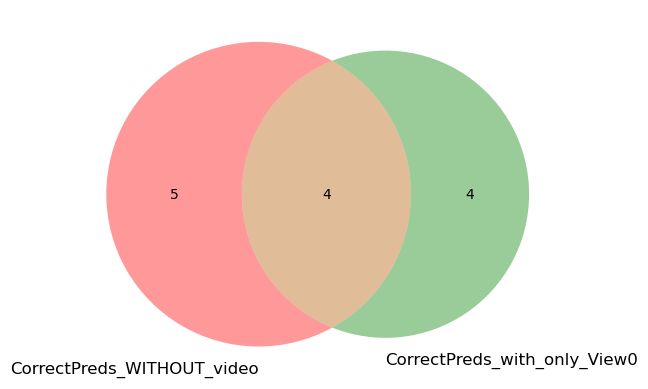

In [28]:
s1 = video_ids_correct_preds_even_without_video
s2 = video_ids_correct_preds_with_only_view0

## conda install -c conda-forge matplotlib-venn
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# Generate and display the Venn diagram
venn2([s1, s2], set_labels=('CorrectPreds_WITHOUT_video', 'CorrectPreds_with_only_View0'))
# plt.title("Venn Diagram of s1 and s2")
plt.show()

## Baseline B: Single View (**View 1** Only)

In [29]:
df_b1 = pd.read_json("data/vlm_eval_results/action_predictions_vqa_2views_recsession5_single_view_cam1.jsonl", lines=True)
print("1: ",df_b1.shape)
print(df_b1.head(2))

index_df['video_file'] = index_df.video_id + '_cam1.avi'
print("2: ", index_df.shape)
print(index_df.head(2))

df_b1 = pd.merge(df_b1, index_df, how = 'left', on = ['video_file']) # LEFT JOIN
print("3: ",df_b1.shape)
print(df_b1.sample(3))

1:  (27, 11)
               video_file          model  elapsed_seconds  prompt_tokens  completion_tokens  total_tokens                                                predicted_class view_0_observation                                                                                                                                                                       view_1_observation                                                                                                                                                                                                                                              combined_reasoning                                                                                                                                                                                                                                                                                                                                                                       

In [30]:
df_b1['correct_top1'] = df_b1['predicted_class'] == df_b1['template']

print(f'      N: {df_b1.shape[0]}')
print(f'correct: {df_b1.correct_top1.sum():4}')
print(f'top1acc: {df_b1.correct_top1.mean():4}')

      N: 27
correct:   21
top1acc: 0.7777777777777778


In [31]:
video_ids_correct_preds_with_only_view1 = df_b1[df_b1.correct_top1]['video_id'].tolist()
video_ids_correct_preds_with_only_view1

['261027-131534',
 '261027-132224',
 '261027-132344',
 '261027-132808',
 '261027-134525',
 '261027-133237',
 '261027-134559',
 '261103-100414',
 '261103-100546',
 '261103-100645',
 '261103-100711',
 '261103-100744',
 '261103-101219',
 '261103-101252',
 '261103-101318',
 '261103-101415',
 '261103-101508',
 '261103-102619',
 '261103-104129',
 '261103-104630',
 '261103-104955']

In [32]:
video_ids_correct_preds_with_only_view1 = {'261027-131534',
 '261027-132224',
 '261027-132344',
 '261027-132808',
 '261027-134525',
 '261027-133237',
 '261027-134559',
 '261103-100414',
 '261103-100546',
 '261103-100645',
 '261103-100711',
 '261103-100744',
 '261103-101219',
 '261103-101252',
 '261103-101318',
 '261103-101415',
 '261103-101508',
 '261103-102619',
 '261103-104129',
 '261103-104630',
 '261103-104955'}

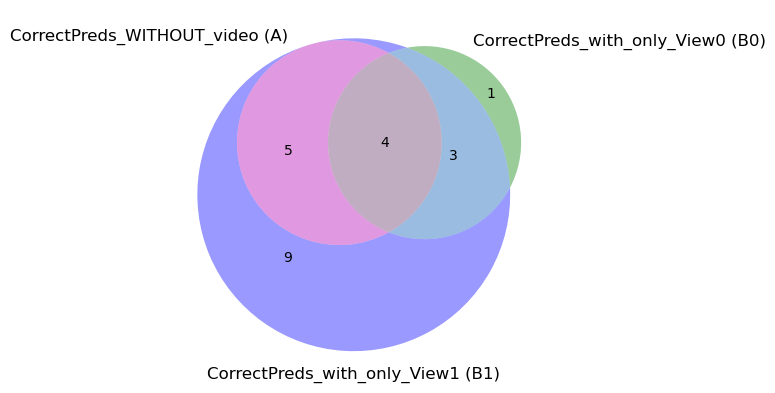

In [60]:
s1 = video_ids_correct_preds_even_without_video
s2 = video_ids_correct_preds_with_only_view0
s3 = video_ids_correct_preds_with_only_view1

## conda install -c conda-forge matplotlib-venn
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

# Generate and display the Venn diagram
venn3([s1, s2, s3], set_labels=('CorrectPreds_WITHOUT_video (A)', 'CorrectPreds_with_only_View0 (B0)', 'CorrectPreds_with_only_View1 (B1)'))
# plt.title("Venn Diagram of s1 and s2")
plt.show()

## Analysis together

In [34]:
df["experiment_type"] = "Main Experiment (both views)"
df_a["experiment_type"] = "Baseline A (no vid)"
df_b0["experiment_type"] = "Baseline B0 (view0)"
df_b1["experiment_type"] = "Baseline B1 (view1)"

In [55]:
import textwrap

pd.set_option('display.float_format', '{:,.3f}'.format)

def analyze_video(video_id_str: str):
    # Find matching row for each dataframe and concatenate into a single 4-row DataFrame
    matched_rows = [
        df[df['video_id'] == video_id_str],
        # df_a[df_a['video_id'] == video_id_str],
        df_b0[df_b0['video_id'] == video_id_str],
        df_b1[df_b1['video_id'] == video_id_str]
    ]
    target_df = pd.concat(matched_rows, ignore_index=True)

    print('=' * 50, video_id_str, '=' * 50)
    for i, row in target_df.iterrows():
        summary_cols = ['video_id', 'session', 'placeholders', 'correct_top1','experiment_type']
        print(row[summary_cols].to_frame().T.to_string(index=False))

        print(f"\n--> template  : {row['template']}")
        print(f"--> prediction: {row['predicted_class']}")

        ranks_data = row['ranks']
        if isinstance(ranks_data, str):
            ranks_data = json.loads(ranks_data)
        
        ranks_series = pd.Series(ranks_data, name="Rank").sort_values()
        
        print('\n------- Rank Distribution (Sorted by Rank): -------')
        print(ranks_series.to_string())
        
        print('\n[*] View 0 Observation:', textwrap.fill(str(row['view_0_observation']), width=100))
        print('[*] View 1 Observation:', textwrap.fill(str(row['view_1_observation']), width=100))
        print('[*] Combined Reasoning:', textwrap.fill(str(row['combined_reasoning']), width=100))
        print('-' * 120)

In [56]:
TOTAL = set(df.video_id.unique().tolist())
A = video_ids_correct_preds_even_without_video
B0 = video_ids_correct_preds_with_only_view0
B1 = video_ids_correct_preds_with_only_view1

print(f"len TOTAL: {len(TOTAL)}")
print(f"len A: {len(A)}")
print(f"len B0: {len(B0)}")
print(f"len B1: {len(B1)}")

len TOTAL: 27
len A: 9
len B0: 8
len B1: 21


In [57]:
## Some examples where both views were necessary for correct prediction:
# - Wrong pred with single view: view0 only
# - Wrong pred with single view: view1 only

TOTAL - B1 - B0

{'261027-132411',
 '261103-101050',
 '261103-101141',
 '261103-104146',
 '261103-104517'}

In [58]:
for video_id in TOTAL - B1 - B0:
    analyze_video(video_id)

================================================== 261103-104146 ==================================================
     video_id          session placeholders correct_top1              experiment_type
261103-104146 vqa2_recsession5         ball        False Main Experiment (both views)

--> template  : Throwing [something] on a surface so it bounces off  and falls
--> prediction: Throwing [something] up in the air and catching it

------- Rank Distribution (Sorted by Rank): -------
Throwing [something] up in the air and catching it                    1
Throwing [something] up in air and wait for it to fall down           2
Throwing [something] on a surface so it bounces off  and falls        3
Throwing [something] on a surface so it rests                         4
Throwing [something] on the ground                                    5
Throwing [something] at the wall so it bounces back                   6
Throwing [something] on a surface and catching it with other hand     7
Throwing

In [65]:
B1.union(B0) - B1

{'261103-104714'}

In [66]:
analyze_video('261103-104714')

================================================== 261103-104714 ==================================================
     video_id          session placeholders correct_top1              experiment_type
261103-104714 vqa2_recsession5 board marker        False Main Experiment (both views)

--> template  : Throwing [something] on the ground
--> prediction: Throwing [something] on a surface so it bounces off  and falls

------- Rank Distribution (Sorted by Rank): -------
Throwing [something] on a surface so it bounces off  and falls        1
Throwing [something] in the [something]                               2
Throwing [something] on the ground                                    3
Throwing [something] on a surface so it rests                         4
Throwing [something] at the wall so it bounces back                   5
Throwing [something] up in air and wait for it to fall down           6
Throwing [something] up in the air and catching it                    7
Throwing [something] on 

In [68]:
## 6 videos where view1 only gave wrong prediction.
for video_id in TOTAL - B1:
    analyze_video(video_id)

================================================== 261103-104146 ==================================================
     video_id          session placeholders correct_top1              experiment_type
261103-104146 vqa2_recsession5         ball        False Main Experiment (both views)

--> template  : Throwing [something] on a surface so it bounces off  and falls
--> prediction: Throwing [something] up in the air and catching it

------- Rank Distribution (Sorted by Rank): -------
Throwing [something] up in the air and catching it                    1
Throwing [something] up in air and wait for it to fall down           2
Throwing [something] on a surface so it bounces off  and falls        3
Throwing [something] on a surface so it rests                         4
Throwing [something] on the ground                                    5
Throwing [something] at the wall so it bounces back                   6
Throwing [something] on a surface and catching it with other hand     7
Throwing